<a href="https://colab.research.google.com/github/paulramirez301206-alt/Ising-model-metropolis-/blob/main/METROPOLIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Algoritmo Metropolis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from tqdm import tqdm

Primero creamos la malla

In [ ]:
def inicio_red(L):
  return np.random.choice([-1,1], size=(L,L))

In [ ]:
def calcular_energia(red, L, J=1.0):
  vecinos_derecha = np.roll(red, shift=1, axis=1)
  vecinos_abajo = np.roll(red, shift=1, axis=0)
  energia = -J * np.sum(red * (vecinos_derecha + vecinos_abajo))
  return energia


*   $S_i$ solo tiene valores {-4,-2,0,2,4} dado que $\sigma_i$ solo es +1 o -1

*   Al querer obtener $\delta E$ multiplicamos por 2, por lo tanto $\delta E = {-8,-4,0,4,8}$

Si tenemos que $\delta E = {-8,-4,0}$ El cambi reduce o mantiene igual la energia. Se acepta con probabilidad 1.

Si tenemos que $\delta E = {8,4}$ LA ENERGIA AUMENTA.




In [ ]:
def tabla_probabilidades(T, J=1.0):
  beta=1.0/T
  return {
      4: np.exp(-4*beta),
      8: np.exp(-8*beta),
  }

def montecarlo(red,L,tabla_w):
    N=L*L
    for _ in range(N):
      # Seleccionar coordenada al azar con dist uniforme
      i=np.random.randint(0,L)
      j=np.random.randint(0,L)

      # Leer estado seleccionado
      sigma_actual=red[i,j]

      #SUMA
      arriba=red[(i+1)%L,j]
      abajo=red[(i-1)%L,j]
      derecha=red[i,(j+1)%L]
      izquierda=red[i,(j-1)%L]

      S_i= arriba+abajo+derecha+izquierda

      #Calculo dif de energia
      dE= 2*sigma_actual*S_i
      if dE<=0 or np.random.rand()<tabla_w[dE]:
        red[i,j]=-sigma_actual





TEMPERATURA

In [ ]:
def simulacion_una_temp(L, T, M_e, M_m):
    N = L * L
    red = inicio_red(L)
    tabla_w = tabla_probabilidades(T)

    # Historial temporal de la energía
    historial_E = []

    # Etapa de equilibración
    for paso in range(M_e):
        montecarlo(red, L, tabla_w)
        E_actual = calcular_energia(red, L) / N
        historial_E.append(E_actual)

    # Etapa de medición
    E_estacionario = []

    for paso in range(M_m):
        montecarlo(red, L, tabla_w)
        E_actual = calcular_energia(red, L) / N

        historial_E.append(E_actual)
        E_estacionario.append(E_actual)

    E_estacionario = np.array(E_estacionario)

    promedio_E = np.mean(E_estacionario)
    varianza_E = np.var(E_estacionario)

    return {
        'red_final': red,
        'historial_E': historial_E,
        'prom_E': promedio_E,
        'var_E': varianza_E
    }




In [ ]:
def temperaturas(L=32, M_equil=1000, M_muestreo=2000):

    temperaturas = [1.5, 2.3, 3.0]

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))

    for idx, T in enumerate(temperaturas):

        res = simulacion_una_temp(L, T, M_equil, M_muestreo)

        # Configuracion final
        axes[idx, 0].imshow(
            res['red_final'],
            cmap='binary',
            vmin=-1,
            vmax=1
        )
        axes[idx, 0].set_title(f"Configuracion final (T = {T})")
        axes[idx, 0].axis('off')

        # Evol final de la energia
        pasos_totales = range(len(res['historial_E']))

        axes[idx, 1].plot(
            pasos_totales,
            res['historial_E'],
            color='crimson'
        )

        axes[idx, 1].axvline(
            x=M_equil,
            color='black',
            linestyle='--',
            label='Fin de equilibracion'
        )

        axes[idx, 1].set_title(f"Energia vs Monte Carlo (T = {T})")
        axes[idx, 1].set_xlabel("Pasos Monte Carlo")
        axes[idx, 1].set_ylabel("Energia por spin")
        axes[idx, 1].legend()
        axes[idx, 1].grid(True)

        # Histograma de energía durante la medición
        energia_medicion = res['historial_E'][M_equil:]
        axes[idx, 2].hist(
            energia_medicion,
            bins=30,
            color='steelblue',
            edgecolor='black'
        )
        axes[idx, 2].set_title(f"Distribucion de energia (T = {T})")
        axes[idx, 2].set_xlabel("Energia por spin")
        axes[idx, 2].set_ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()




def barrido_temperatura(
    L=32,
    num_puntos_T=20,
    M_equil=1500,
    M_muestreo=3000
):

    lista_T = np.linspace(1.5, 3.0, num_puntos_T)

    promedios_E = []
    varianzas_E = []

    print("Iniciando barrido de temperatura...")

    for T in lista_T:

        res = simulacion_una_temp(L, T, M_equil, M_muestreo)

        promedios_E.append(res['prom_E'])
        varianzas_E.append(res['var_E'])

        print(
            f"T = {T:.2f} | "
            f"<E> = {res['prom_E']:.4f} | "
            f"Var(E) = {res['var_E']:.4f}"
        )

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # Energia promedio vs temperatura
    axes[0, 0].plot(
        lista_T, promedios_E,
        'o-', color='crimson'
    )
    axes[0, 0].axvline(
        x=2.27, color='grey',
        linestyle='--', label='Tc ≈ 2.27'
    )
    axes[0, 0].set_title("Energia promedio <E> vs T")
    axes[0, 0].set_xlabel("Temperatura reducida T")
    axes[0, 0].set_ylabel("Energia por spin")
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # Varianza de la energia vs temperatura
    axes[1, 0].plot(
        lista_T, varianzas_E,
        's-', color='darkred'
    )
    axes[1, 0].axvline(
        x=2.27, color='grey',
        linestyle='--', label='Tc ≈ 2.27'
    )
    axes[1, 0].set_title("Varianza de la energia vs T")
    axes[1, 0].set_xlabel("Temperatura reducida T")
    axes[1, 0].set_ylabel("Var(E)")
    axes[1, 0].legend()
    axes[1, 0].grid(True)


    axes[0, 1].axis('off')
    axes[1, 1].axis('off')

    plt.tight_layout()
    plt.show()

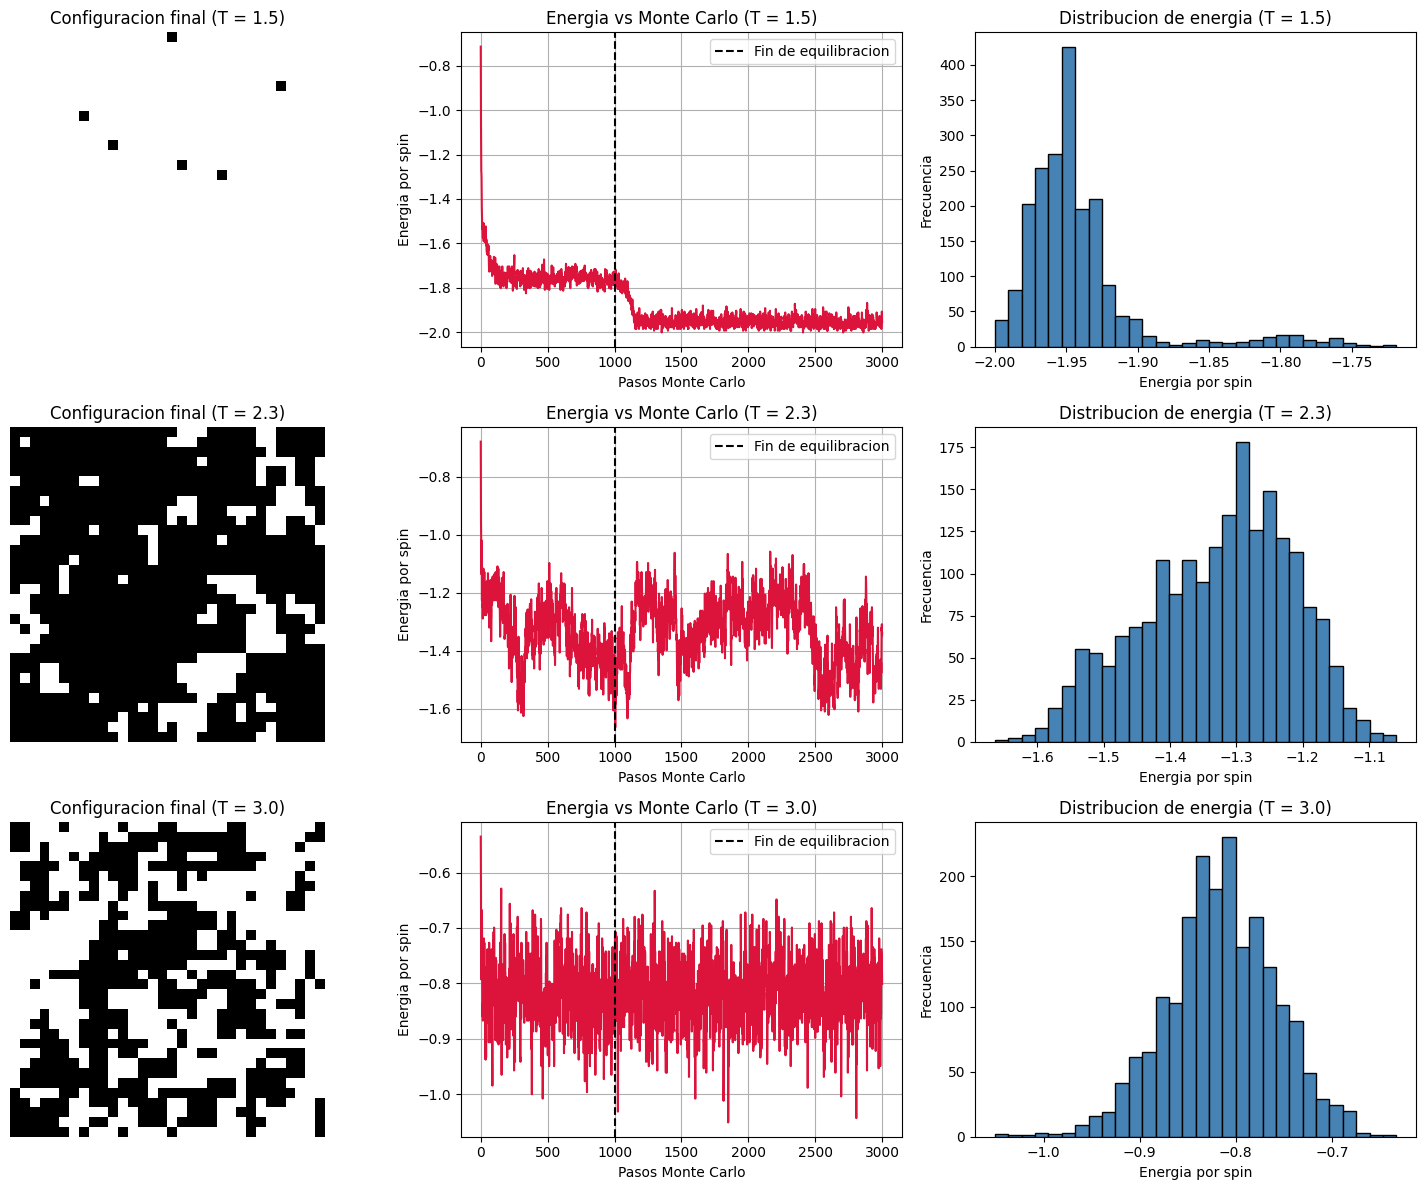

Iniciando barrido de temperatura...
T = 1.50 | <E> = -1.9504 | Var(E) = 0.0005
T = 1.58 | <E> = -1.9343 | Var(E) = 0.0006
T = 1.66 | <E> = -1.9105 | Var(E) = 0.0009
T = 1.74 | <E> = -1.8836 | Var(E) = 0.0011
T = 1.82 | <E> = -1.8519 | Var(E) = 0.0015
T = 1.89 | <E> = -1.8125 | Var(E) = 0.0019
T = 1.97 | <E> = -1.7663 | Var(E) = 0.0023
T = 2.05 | <E> = -1.7056 | Var(E) = 0.0036
T = 2.13 | <E> = -1.6382 | Var(E) = 0.0042
T = 2.21 | <E> = -1.5346 | Var(E) = 0.0063
T = 2.29 | <E> = -1.3928 | Var(E) = 0.0081
T = 2.37 | <E> = -1.2511 | Var(E) = 0.0076
T = 2.45 | <E> = -1.1550 | Var(E) = 0.0062
T = 2.53 | <E> = -1.0828 | Var(E) = 0.0055
T = 2.61 | <E> = -1.0279 | Var(E) = 0.0048
T = 2.68 | <E> = -0.9701 | Var(E) = 0.0041
T = 2.76 | <E> = -0.9277 | Var(E) = 0.0042
T = 2.84 | <E> = -0.8878 | Var(E) = 0.0040
T = 2.92 | <E> = -0.8499 | Var(E) = 0.0037
T = 3.00 | <E> = -0.8208 | Var(E) = 0.0037


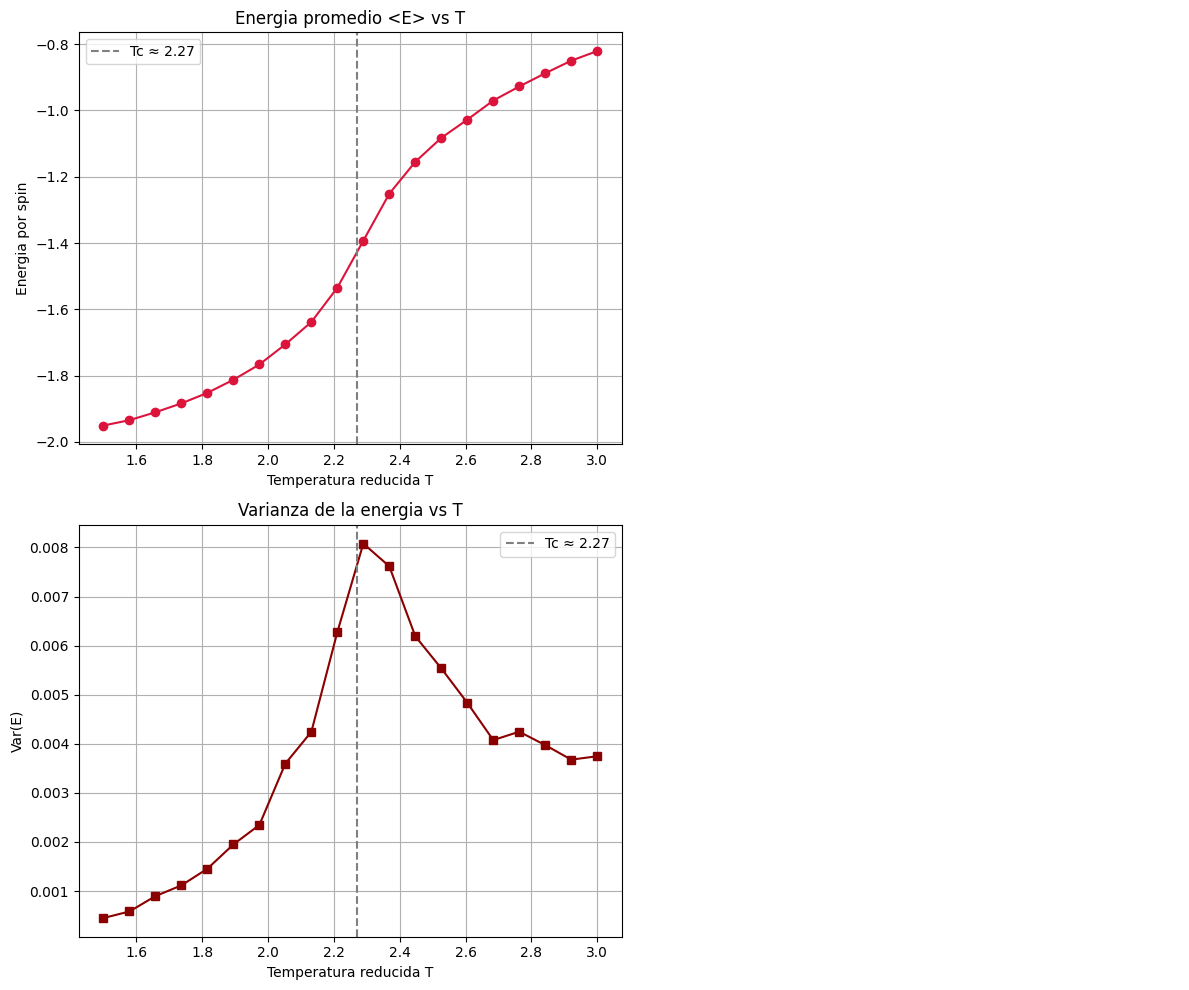

In [ ]:
temperaturas()
barrido_temperatura()